# 02. Baseline Model Training Plant Disease Classification

## 1. Introduction

This notebook focuses on developing and evaluating a baseline deep learning model for the PlantVillage plant disease classification project.

In the previous notebook (`01_data_understanding.ipynb`), we explored, cleaned, and validated the dataset. We prepared three leakage-free datasets:

- **Training set:** 34,880 images
- **Validation set:** 8,702 images
- **Testing set:** 10,464 images

The prepared dataset contains **38 plant disease and healthy-condition classes across 14 crops**. All images have been standardized to RGB format and resized to 256 × 256 pixels.

### 1.1 Objectives

The main objectives of this notebook are to:

1. Load and inspect the prepared training, validation, and testing datasets.
2. Apply the preprocessing required by our selected pretrained architecture.
3. Develop a baseline image classification model using transfer learning.
4. Train the model and monitor training and validation performance.
5. Apply optimization techniques such as suitable optimizers, regularization, and early stopping.
6. Evaluate model performance using accuracy, precision, recall, F1-score, loss, and a confusion matrix.
7. Save the trained model and class mapping for future prediction and deployment.

### 1.2 Modeling Approach

We will begin with a pretrained convolutional neural network and adapt its classification head to recognize the 38 target classes.

Transfer learning allows us to leverage features learned from a large image dataset rather than training an entire deep learning architecture from scratch.

We will initially freeze the pretrained feature extraction layers and train the classification head. Depending on the baseline results, we may fine-tune selected layers to improve performance.

### 1.3 Expected Outputs

By the end of this notebook, we aim to produce:

- A trained baseline classification model.
- Training and validation performance visualizations.
- A comprehensive evaluation report.
- A confusion matrix and per-class performance metrics.
- A saved model ready for prediction and further development.



In [4]:
# Install the dataset library
!pip install -q datasets

In [6]:
# General libraries
import os
import json
import zipfile
import random
from pathlib import Path
import shutil
import math


# Data handling
import numpy as np
import pandas as pd

# Image handling and visualization
import matplotlib.pyplot as plt
from PIL import Image

# Hugging Face datasets
from datasets import load_from_disk

import tensorflow as tf
from tensorflow.keras import layers, regularizers, Model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay



# Reproducibility
random.seed(42)
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [4]:
!pip install -q gdown

In [7]:
import gdown

drive_url = "https://drive.google.com/file/d/1F0x6ebeBKpoToHuw1dwDrVGrzFXed4yA/view?usp=sharing"

output_path = "/kaggle/working/plantvillage_prepared.zip"

gdown.download(
    drive_url,
    output_path,
    quiet=False,
    fuzzy=True
)

Downloading...
From (original): https://drive.google.com/uc?id=1F0x6ebeBKpoToHuw1dwDrVGrzFXed4yA
From (redirected): https://drive.google.com/uc?id=1F0x6ebeBKpoToHuw1dwDrVGrzFXed4yA&confirm=t&uuid=7a7bf2a7-ab74-4c98-ac8e-c47e00389a11
To: /kaggle/working/plantvillage_prepared.zip
100%|██████████| 860M/860M [00:09<00:00, 86.2MB/s] 


'/kaggle/working/plantvillage_prepared.zip'

In [8]:
zip_path = "/kaggle/working/plantvillage_prepared.zip"

if os.path.exists(zip_path):
    print(f"Download successful!")
    print(f"File size: {os.path.getsize(zip_path) / (1024**3):.2f} GB")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        print("ZIP file is valid:", zip_ref.testzip() is None)
else:
    print("Download failed. Check the Google Drive link.")

Download successful!
File size: 0.80 GB
ZIP file is valid: True


In [9]:
zip_path = Path("/kaggle/working/plantvillage_prepared.zip")

# Extraction directory
data_dir = Path("/kaggle/working")

# Extracted dataset location
dataset_path = data_dir / "plantvillage_prepared"

print("ZIP path:", zip_path)
print("ZIP exists:", zip_path.exists())
print("Dataset path:", dataset_path)

ZIP path: /kaggle/working/plantvillage_prepared.zip
ZIP exists: True
Dataset path: /kaggle/working/plantvillage_prepared


In [11]:
if dataset_path.exists():
    print("Prepared dataset folder already exists.")

else:
    if not zip_path.exists():
        raise FileNotFoundError(f"ZIP file not found: {zip_path}")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        corrupted_file = zip_ref.testzip()

        if corrupted_file is not None:
            raise ValueError(f"Corrupted ZIP member: {corrupted_file}")

        zip_ref.extractall(data_dir)

    print("Dataset extracted successfully!")

print("Dataset directory:", dataset_path)

Prepared dataset folder already exists.
Dataset directory: /kaggle/working/plantvillage_prepared


we are training an image classification model using transfer learning, we will check the TensorFlow version and GPU availability. We will also confirm that the prepared training, validation, and testing datasets are accessible.

This ensures that our training environment is configured correctly before starting model development.

In [13]:
print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", gpus)

if gpus:
    print("GPU is ready for training!")
else:
    print("GPU is still unavailable. Check runtime settings.")

TensorFlow version: 2.21.0
TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
GPU is ready for training!


In [14]:
dataset_path = Path("/kaggle/working/plantvillage_prepared")
# Load datasets
prepared_datasets = load_from_disk(str(dataset_path))

train_data = prepared_datasets["train"]
val_data = prepared_datasets["validation"]
test_data = prepared_datasets["test"]

# Retrieve class names
class_names = train_data.features["label"].names

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [15]:
# Dataset sizes
print("\nDATASET SIZES")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

# Class information
print("\nCLASS INFORMATION")
print("Number of classes:", len(class_names))
print("First five classes:", class_names[:5])

# Verify expected values
assert len(train_data) == 34880
assert len(val_data) == 8702
assert len(test_data) == 10464
assert len(class_names) == 38

print("\nAll dataset checks passed!")


DATASET SIZES
Training: 34880
Validation: 8702
Testing: 10464

CLASS INFORMATION
Number of classes: 38
First five classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']

All dataset checks passed!


### 2.2 Image Preprocessing

In this section, we will prepare the PlantVillage images for our MobileNetV2 transfer-learning model.

The original images are RGB and have dimensions of 256 × 256 pixels. However, MobileNetV2 will receive images resized to 224 × 224 pixels.

We will also apply the preprocessing function recommended for MobileNetV2, which scales pixel values from the original range of [0, 255] to [-1, 1].

Data augmentation will be applied exclusively to the training dataset to improve the model's ability to generalize to unseen images. Validation and testing images will only undergo resizing and normalization.

In [16]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Image configuration
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

print("Image preprocessing configuration:")
print("Target image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Number of classes:", NUM_CLASSES)

Image preprocessing configuration:
Target image size: 224 x 224
Batch size: 32
Number of classes: 38


Original image shape: (256, 256, 3)
Original image data type: uint8
Original pixel range: 0 to 255
Image class: Raspberry___healthy


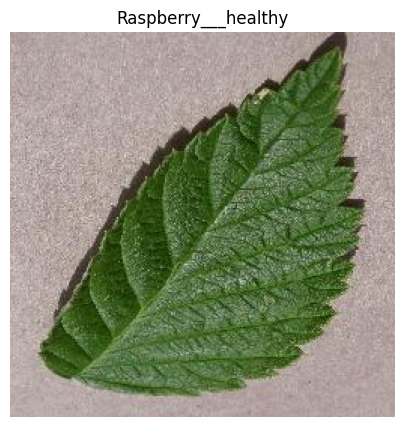

In [17]:
# Select one training image
sample = train_data[0]

original_image = np.array(
    sample["image"].convert("RGB")
)

original_label = sample["label"]

print("Original image shape:", original_image.shape)
print("Original image data type:", original_image.dtype)
print("Original pixel range:",
      original_image.min(), "to", original_image.max())
print("Image class:", class_names[original_label])

# Display original image
plt.figure(figsize=(5, 5))
plt.imshow(original_image)
plt.title(class_names[original_label])
plt.axis("off")
plt.show()

In [20]:
def preprocess_image(image):
    """
    Resize an image to 224x224 and apply
    MobileNetV2 preprocessing.
    """

    # Ensure RGB format
    image = image.convert("RGB")

    # Convert image to NumPy array
    image = np.array(image, dtype=np.float32)

    # Convert to TensorFlow tensor
    image = tf.convert_to_tensor(image)

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Apply MobileNetV2 preprocessing
    image = preprocess_input(image)

    return image

In [21]:
# Preprocess one sample image
processed_image = preprocess_image(sample["image"])

print("Processed image shape:", processed_image.shape)
print("Processed image data type:", processed_image.dtype)
print(
    "Processed pixel range:",
    float(tf.reduce_min(processed_image)),
    "to",
    float(tf.reduce_max(processed_image))
)

Processed image shape: (224, 224, 3)
Processed image data type: <dtype: 'float32'>
Processed pixel range: -1.0 to 0.7992373704910278


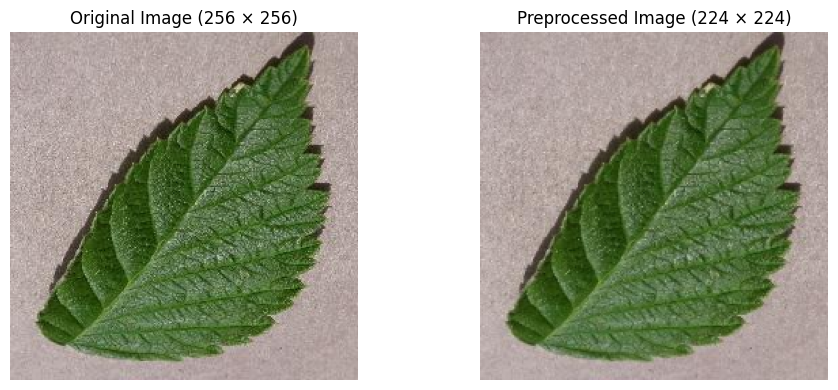

In [22]:
# Convert normalized image back to display range
display_image = (processed_image.numpy() + 1.0) / 2.0

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image (256 × 256)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(np.clip(display_image, 0, 1))
plt.title("Preprocessed Image (224 × 224)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    )
], name="data_augmentation")

print("Data augmentation pipeline created!")

Data augmentation pipeline created!


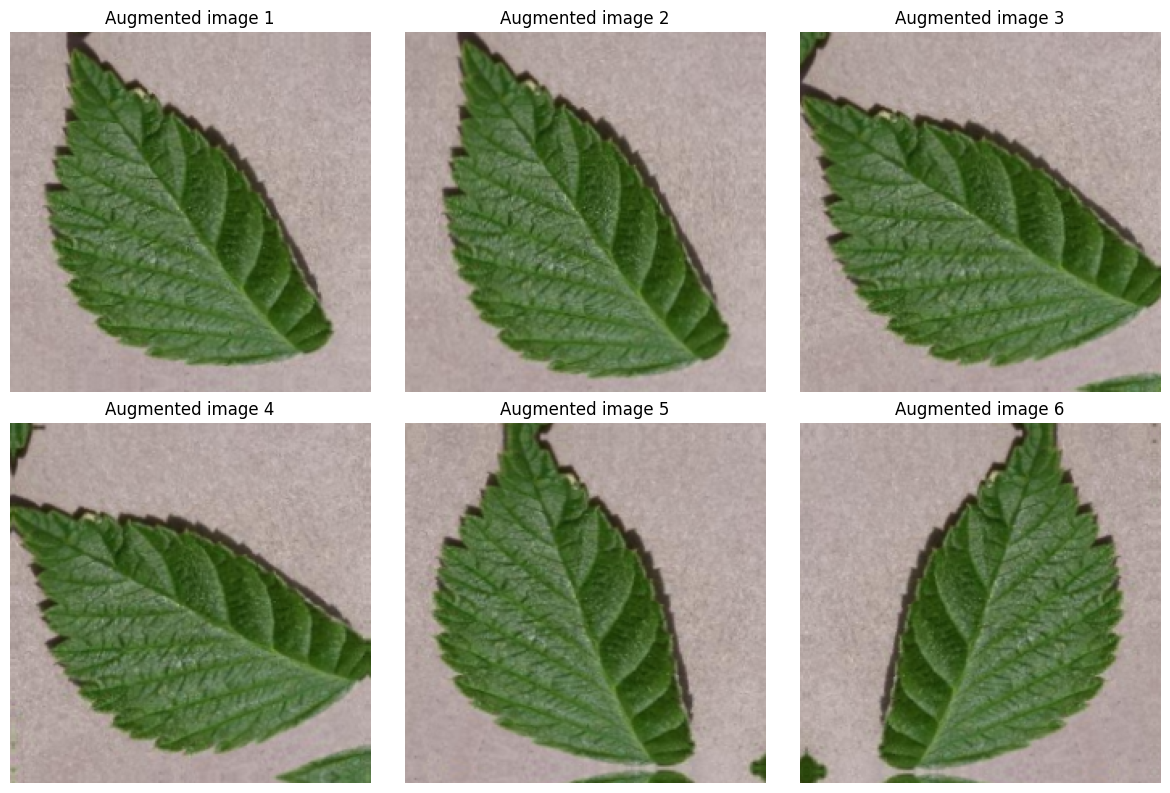

In [25]:
# Resize the sample without normalization
resized_sample = tf.image.resize(
    original_image.astype(np.float32),
    [IMG_SIZE, IMG_SIZE]
)

plt.figure(figsize=(12, 8))

for i in range(6):
    augmented_image = data_augmentation(
        tf.expand_dims(resized_sample, axis=0),
        training=True
    )

    # Convert back to display range
    augmented_image = tf.clip_by_value(
        augmented_image[0] / 255.0,
        0,
        1
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(augmented_image.numpy())
    plt.title(f"Augmented image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [26]:
print("Preprocessing Verfication")

print("Original shape:", original_image.shape)
print("Processed shape:", processed_image.shape)

print(
    "Normalized pixel range:",
    float(tf.reduce_min(processed_image)),
    "to",
    float(tf.reduce_max(processed_image))
)

assert processed_image.shape == (224, 224, 3)
assert float(tf.reduce_min(processed_image)) >= -1.0
assert float(tf.reduce_max(processed_image)) <= 1.0

print("\nPreprocessing verification passed!")

Preprocessing Verfication
Original shape: (256, 256, 3)
Processed shape: (224, 224, 3)
Normalized pixel range: -1.0 to 0.7992373704910278

Preprocessing verification passed!


### 2.3 Building TensorFlow Data Pipelines

The prepared datasets are stored as Hugging Face datasets. We will convert them into TensorFlow-compatible datasets using `tf.data.Dataset.from_generator`.

This approach allows us to load images progressively rather than converting all images into large in-memory arrays.

We will create separate pipelines for training, validation, and testing, ensuring that augmentation and shuffling are applied only where appropriate.

In [27]:
def hf_dataset_generator(hf_dataset):
    """
    Generate RGB image arrays and integer labels
    from a Hugging Face dataset.
    """

    for example in hf_dataset:
        image = example["image"].convert("RGB")

        image = np.asarray(image, dtype=np.uint8)
        label = np.int64(example["label"])

        yield image, label


# Define the expected image and label structures
output_signature = (
    tf.TensorSpec(
        shape=(256, 256, 3),
        dtype=tf.uint8
    ),
    tf.TensorSpec(
        shape=(),
        dtype=tf.int64
    )
)

print("Data generator and output signature defined successfully!")

Data generator and output signature defined successfully!


In [28]:
train_raw = tf.data.Dataset.from_generator(
    lambda: hf_dataset_generator(train_data),
    output_signature=output_signature
)

val_raw = tf.data.Dataset.from_generator(
    lambda: hf_dataset_generator(val_data),
    output_signature=output_signature
)

test_raw = tf.data.Dataset.from_generator(
    lambda: hf_dataset_generator(test_data),
    output_signature=output_signature
)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [29]:
data_augmentation = tf.keras.Sequential([
    tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    tf.keras.layers.RandomFlip("horizontal"),

    tf.keras.layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect"
    ),

    tf.keras.layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    )

], name="data_augmentation")

print("Augmentation pipeline recreated successfully!")

Augmentation pipeline recreated successfully!


In [30]:
def preprocess_training(image, label):

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Add temporary batch dimension
    image = tf.expand_dims(image, axis=0)

    # Apply augmentation
    image = data_augmentation(
        image,
        training=True
    )

    # Remove temporary batch dimension
    image = tf.squeeze(image, axis=0)

    # Apply MobileNetV2 normalization
    image = preprocess_input(image)

    return image, label


def preprocess_evaluation(image, label):
    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # No augmentation for validation or testing
    image = preprocess_input(image)

    return image, label


print("Training and evaluation preprocessing functions defined!")

Training and evaluation preprocessing functions defined!


In [31]:
AUTOTUNE = tf.data.AUTOTUNE

# Training pipeline
train_dataset = (
    train_raw
    .shuffle(
        buffer_size=1000,
        seed=42,
        reshuffle_each_iteration=True
    )
    .map(
        preprocess_training,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Validation pipeline
val_dataset = (
    val_raw
    .map(
        preprocess_evaluation,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# Testing pipeline
test_dataset = (
    test_raw
    .map(
        preprocess_evaluation,
        num_parallel_calls=AUTOTUNE
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("All three TensorFlow data pipelines created successfully!")

All three TensorFlow data pipelines created successfully!


In [32]:
def inspect_pipeline(dataset, name):
    images, labels = next(iter(dataset))

    print(f"\n{name} PIPELINE")
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Label data type:", labels.dtype)
    print(
        "Pixel range:",
        float(tf.reduce_min(images)),
        "to",
        float(tf.reduce_max(images))
    )
    print("First five labels:", labels[:5].numpy())

    # Verify image dimensions and normalization
    assert images.shape[1:] == (224, 224, 3)
    assert labels.dtype == tf.int64
    assert float(tf.reduce_min(images)) >= -1.0
    assert float(tf.reduce_max(images)) <= 1.0


inspect_pipeline(train_dataset, "TRAINING")
inspect_pipeline(val_dataset, "VALIDATION")
inspect_pipeline(test_dataset, "TESTING")

print("\nAll pipeline checks passed!")


TRAINING PIPELINE
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Pixel range: -0.9999983906745911 to 1.0
First five labels: [23  7 23 23 21]

VALIDATION PIPELINE
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Pixel range: -1.0 to 0.9625824689865112
First five labels: [23 23 23 23 23]

TESTING PIPELINE
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Label data type: <dtype: 'int64'>
Pixel range: -1.0 to 1.0
First five labels: [23 23 23 23 23]

All pipeline checks passed!


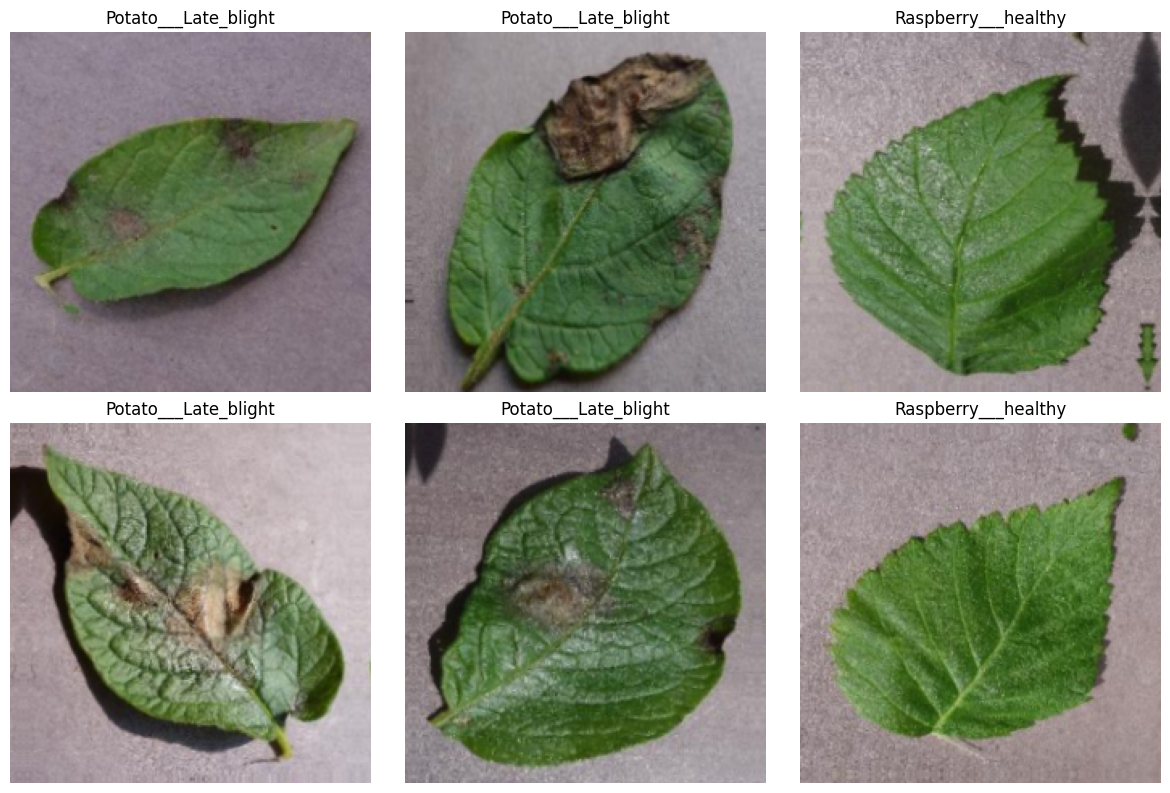

In [33]:
images, labels = next(iter(train_dataset))

plt.figure(figsize=(12, 8))

for i in range(6):
    display_image = (images[i].numpy() + 1.0) / 2.0

    plt.subplot(2, 3, i + 1)
    plt.imshow(np.clip(display_image, 0, 1))
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [34]:
# Use the same original image twice
test_image = tf.cast(
    tf.convert_to_tensor(original_image),
    tf.uint8
)

test_label = tf.constant(0, dtype=tf.int64)

# Apply training preprocessing twice
train_image_1, _ = preprocess_training(
    test_image, test_label
)

train_image_2, _ = preprocess_training(
    test_image, test_label
)

# Apply evaluation preprocessing twice
eval_image_1, _ = preprocess_evaluation(
    test_image, test_label
)

eval_image_2, _ = preprocess_evaluation(
    test_image, test_label
)

# Calculate differences
training_difference = tf.reduce_mean(
    tf.abs(train_image_1 - train_image_2)
)

evaluation_difference = tf.reduce_max(
    tf.abs(eval_image_1 - eval_image_2)
)

print("Training image difference:", float(training_difference))
print("Evaluation image difference:", float(evaluation_difference))

Training image difference: 0.29932117462158203
Evaluation image difference: 0.0


### 2.4 Building the Baseline Model Using MobileNetV2

In this section, we will develop a baseline plant disease classification model using transfer learning.

We will use MobileNetV2 with pretrained ImageNet weights as the feature extraction backbone. Its original classification head will be excluded and replaced with a custom classification head designed for our 38 target classes.

Initially, the pretrained layers will be frozen to preserve their learned features while the new classification head is trained.

To improve generalization and reduce overfitting, the classification head will include:

- Global Average Pooling to reduce the dimensionality of extracted feature maps.
- Dropout regularization to reduce dependency on individual neurons.
- L2 kernel regularization to penalize excessively large weights.
- A Dense output layer with 38 neurons and softmax activation.

The model will be compiled using the Adam optimizer and sparse categorical cross-entropy loss.

In [28]:
# Load MobileNetV2 with ImageNet pretrained weights
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")
print("Total backbone layers:", len(base_model.layers))
print("Trainable backbone:", base_model.trainable)

MobileNetV2 loaded successfully!
Total backbone layers: 154
Trainable backbone: False


In [29]:
# Define model input
inputs = layers.Input(
    shape=(IMG_SIZE, IMG_SIZE, 3),
    name="input_image"
)

# Extract features using MobileNetV2
x = base_model(
    inputs,
    training=False
)

# Reduce spatial dimensions
x = layers.GlobalAveragePooling2D(
    name="global_average_pooling"
)(x)

# Apply dropout regularization
x = layers.Dropout(
    0.3,
    name="dropout"
)(x)

# Final classification layer
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax",
    kernel_regularizer=regularizers.l2(0.0001),
    name="classification_head"
)(x)

# Build complete model
model = Model(
    inputs=inputs,
    outputs=outputs,
    name="plant_disease_mobilenetv2"
)

print("Baseline MobileNetV2 model created successfully!")

Baseline MobileNetV2 model created successfully!


In [30]:
# Compile the baseline model
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=[
        "accuracy"
    ]
)

print("Model compiled successfully!")

Model compiled successfully!


In [31]:

# Create directory for model artifacts
model_dir = Path("/kaggle/working/plant_disease_artifacts")
model_dir.mkdir(parents=True, exist_ok=True)

# Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

# Reduce learning rate when validation loss plateaus
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

# Save the best model
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=str(model_dir / "best_mobilenetv2.keras"),
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr,
    model_checkpoint
]

print("Training callbacks configured successfully!")

Training callbacks configured successfully!


This is an encouraging first experiment. However, validation accuracy alone is not enough to decide that this is our final model. We still need precision, recall, F1-score and loss, particularly because our dataset has class imbalance.

In [32]:
EPOCHS = 50

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/50
   1090/Unknown 215s 185ms/step - accuracy: 0.8211 - loss: 0.7514

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 4.36699, saving model to /kaggle/working/plant_disease_artifacts/best_mobilenetv2.keras

Epoch 1: finished saving model to /kaggle/working/plant_disease_artifacts/best_mobilenetv2.keras
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 235s 204ms/step - accuracy: 0.8579 - loss: 0.6394 - val_accuracy: 0.2407 - val_loss: 4.3670 - learning_rate: 0.0010
Epoch 2/50
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.8844 - loss: 0.7351
Epoch 2: val_loss improved from 4.36699 to 2.36709, saving model to /kaggle/working/plant_disease_artifacts/best_mobilenetv2.keras

Epoch 2: finished saving model to /kaggle/working/plant_disease_artifacts/best_mobilenetv2.keras
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 226s 206ms/step - accuracy: 0.9276 - loss: 0.3509 - val_accuracy: 0.4675 - val_loss: 2.3671 - learning_rate: 0.0010
Epoch 3/50
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.9394 - loss: 0.2857
Epoch 3: val_loss improved from 2.36709 to 2.13963, saving model to /k

This is an encouraging first experiment. However, validation accuracy alone is not enough to decide that this is our final model. We still need precision, recall, F1-score and loss, particularly because our dataset has class imbalance.

In [47]:
best_model_path = Path(
    "/kaggle/input/datasets/janvieremunezero/leaflens-trained-models/best_mobilenetv2.keras"
)

if not best_model_path.exists():
    raise FileNotFoundError(
        f"Best model not found: {best_model_path}"
    )

best_model = tf.keras.models.load_model(best_model_path)

print("Best model loaded successfully!")


Best model loaded successfully!


In [34]:

val_loss, val_accuracy = best_model.evaluate(
    val_dataset,
    verbose=1
)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")


272/272 ━━━━━━━━━━━━━━━━━━━━ 19s 54ms/step - accuracy: 0.9408 - loss: 0.2301
Validation Loss: 0.2301
Validation Accuracy: 0.9408


In [35]:
y_prob = best_model.predict(
    val_dataset,
    verbose=1
)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Collect actual labels
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_dataset
])

print("Actual labels shape:", y_true.shape)
print("Predicted labels shape:", y_pred.shape)


272/272 ━━━━━━━━━━━━━━━━━━━━ 19s 56ms/step
Actual labels shape: (8702,)
Predicted labels shape: (8702,)


In [36]:

metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Loss": val_loss,

    "Macro Precision": precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro Recall": recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    ),

    "Macro F1-score": f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    ),

    "Precision": precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    ),

    "Recall": recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    ),

    "F1-score": f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )
}

evaluation_table = pd.DataFrame(
    metrics.items(),
    columns=["Evaluation Metric", "Experiment 1"]
)

evaluation_table["Experiment 1"] = (
    evaluation_table["Experiment 1"].round(4)
)

display(evaluation_table)


,Evaluation Metric,Experiment 1
0,Accuracy,0.9408
1,Loss,0.2301
2,Macro Precision,0.9367
3,Macro Recall,0.9131
4,Macro F1-score,0.9205
5,Precision,0.9417
6,Recall,0.9408
7,F1-score,0.9389


Experiment 1 demonstrates that the frozen MobileNetV2 feature extractor provides a strong starting point for the plant disease classification task. The model achieved 94.08% validation accuracy and a macro F1-score of 92.24% across the 38 classes.

However, the difference between macro recall (91.53%) and weighted recall (94.08%) indicates that we should investigate individual class performance before considering the baseline fully satisfactory. The per-class classification report will help identify classes where the model struggles.

**Next step:** I will conduct Experiment 2 by fine-tuning selected layers of the pretrained MobileNetV2 model using a lower learning rate. The objective is to determine whether allowing some pretrained feature-extraction layers to adapt to the PlantVillage dataset can improve validation performance, particularly macro recall and macro F1-score.

The validation dataset will be used to compare the experiments and select the best model. The held-out test dataset will remain untouched until final evaluation.

In [37]:

class_report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

class_report_df = pd.DataFrame(class_report).transpose()

display(
    class_report_df.round(4)
)


,precision,recall,f1-score,support
Apple___Apple_scab,0.9351,0.8571,0.8944,84.0000
Apple___Black_rot,0.9765,1.0000,0.9881,83.0000
Apple___Cedar_apple_rust,1.0000,0.9767,0.9882,43.0000
Apple___healthy,0.9821,0.9786,0.9804,281.0000
Blueberry___healthy,0.9920,0.9920,0.9920,249.0000
Cherry_(including_sour)___Powdery_mildew,1.0000,0.9931,0.9965,144.0000
Cherry_(including_sour)___healthy,0.9787,0.9452,0.9617,146.0000
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.8642,0.7447,0.8000,94.0000
Corn_(maize)___Common_rust_,0.9848,1.0000,0.9924,195.0000
Corn_(maize)___Northern_Leaf_Blight,0.8452,0.9281,0.8847,153.0000



## Experiment 2: Fine-Tuning the Pretrained MobileNetV2 Model

Following the evaluation of Experiment 1, we identified that the baseline model achieved strong overall performance, with 94.08% validation accuracy and a macro F1-score of 92.24%. However, the per-class classification report revealed that some disease categories, particularly Tomato Early Blight, Potato Healthy, and Tomato Target Spot, were not identified as reliably as other classes.

To investigate whether the model's feature extraction capabilities can be improved, Experiment 2 introduces **fine-tuning of the pretrained MobileNetV2 model**.

In Experiment 1, the pretrained MobileNetV2 base model was frozen, meaning that its ImageNet weights remained unchanged during training. Only the custom classification head was trained to recognize the 38 plant disease classes.

In this experiment, we will unfreeze the final 30 layers of the MobileNetV2 feature extractor while keeping its earlier layers frozen. This allows the deeper feature extraction layers to adapt to the visual characteristics of plant diseases while retaining the general features learned during ImageNet pretraining.

The following configuration will be used:

- **Pretrained architecture:** MobileNetV2
- **Trainable layers:** Final 30 layers of the feature extractor, excluding Batch Normalization layers
- **Learning rate:** 0.00001 (1e-5)
- **Optimizer:** Adam
- **Loss function:** Sparse Categorical Crossentropy
- **Maximum epochs:** 30
- **Early stopping:** Monitors validation loss to prevent unnecessary training
- **Learning rate reduction:** ReduceLROnPlateau
- **Model checkpoint:** Saves the best model based on validation loss

A lower learning rate is used during fine-tuning to make smaller weight updates and reduce the risk of disrupting the useful pretrained representations.

The objective is to determine whether fine-tuning improves the model's overall performance, particularly macro recall and macro F1-score, while also addressing weaknesses observed in individual disease classes.

The results will be compared against Experiment 1 using the same validation dataset and evaluation metrics.


In [54]:
# Identify the nested MobileNetV2 feature extractor
base_model_candidates = [
    layer for layer in best_model.layers
    if isinstance(layer, tf.keras.Model)
]

if len(base_model_candidates) != 1:
    raise ValueError(
        f"Expected one nested feature extractor, "
        f"but found {len(base_model_candidates)}. "
        "Inspect best_model.summary() before proceeding."
    )

base_model = base_model_candidates[0]

print("Feature extractor:", base_model.name)
print("Total layers:", len(base_model.layers))

Feature extractor: mobilenetv2_1.00_224
Total layers: 154


In [55]:
# Unfreeze the feature extractor
base_model.trainable = True

# Freeze all layers except the final 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Display trainable and non-trainable layer counts
trainable_layers = sum(
    layer.trainable for layer in base_model.layers
)

non_trainable_layers = len(base_model.layers) - trainable_layers

print("Trainable layers:", trainable_layers)
print("Non-trainable layers:", non_trainable_layers)

Trainable layers: 19
Non-trainable layers: 135


In [56]:
experiment2_model = best_model

experiment2_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Experiment 2 model compiled successfully.")

Experiment 2 model compiled successfully.


In [58]:
EXPERIMENT2_DIR = Path.cwd() / "plant_disease_artifacts"
EXPERIMENT2_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = EXPERIMENT2_DIR / "best_mobilenetv2_finetuned.keras"

callbacks_experiment2 = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        str(EXPERIMENT2_DIR / "experiment2_training_log.csv")
    )
]

print("Experiment 2 callbacks configured.")
print("Checkpoint:", checkpoint_path)

Experiment 2 callbacks configured.
Checkpoint: /kaggle/working/plant_disease_artifacts/best_mobilenetv2_finetuned.keras


In [42]:
EPOCHS= 30

history_experiment2 = experiment2_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks_experiment2,
    verbose=1
)

Epoch 1/30


E0000 00:00:1795426538.602287    1356 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


   1090/Unknown 222s 192ms/step - accuracy: 0.9784 - loss: 0.1058

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 0.63463, saving model to /kaggle/working/plant_disease_artifacts/best_mobilenetv2_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/plant_disease_artifacts/best_mobilenetv2_finetuned.keras
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 240s 209ms/step - accuracy: 0.9789 - loss: 0.1013 - val_accuracy: 0.8379 - val_loss: 0.6346 - learning_rate: 1.0000e-05
Epoch 2/30
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 0.9692 - loss: 0.1383
Epoch 2: val_loss did not improve from 0.63463
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 226s 206ms/step - accuracy: 0.9780 - loss: 0.1045 - val_accuracy: 0.8242 - val_loss: 0.6769 - learning_rate: 1.0000e-05
Epoch 3/30
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step - accuracy: 0.9701 - loss: 0.1236
Epoch 3: val_loss did not improve from 0.63463
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 226s 206ms/step - accuracy: 0.9802 - loss: 0.0942 - val_accuracy: 0.8384 - val_loss: 0.6420 - learning_rate: 1.0000e-05
Epoch 4/30
1090/1090 ━━━━━

In [49]:
# Source checkpoint created during training
source_checkpoint = Path(
    "/kaggle/working/plant_disease_artifacts/"
    "best_mobilenetv2_finetuned.keras"
)

# Dedicated Experiment 2 folder
experiment2_dir = Path(
    "/kaggle/working/plant_disease_artifacts/"
    "experiment_02_finetuning"
)
experiment2_dir.mkdir(parents=True, exist_ok=True)

# 1. Verify and preserve the best checkpoint
if not source_checkpoint.exists():
    raise FileNotFoundError(
        f"Experiment 2 checkpoint not found: {source_checkpoint}"
    )

saved_model_path = (
    experiment2_dir / "best_mobilenetv2_finetuned.keras"
)

shutil.copy2(source_checkpoint, saved_model_path)

# 2. Save epoch-by-epoch training history
history_df = pd.DataFrame(history_experiment2.history)
history_df.index = history_df.index + 1
history_df.index.name = "epoch"

history_path = experiment2_dir / "training_history.csv"
history_df.to_csv(history_path)

# 3. Save experiment configuration and best logged results
experiment_metadata = {
    "experiment": "Experiment 2 - MobileNetV2 Fine-Tuning",
    "architecture": "MobileNetV2",
    "trainable_base_layers": 19,
    "non_trainable_base_layers": 135,
    "learning_rate_initial": 0.00001,
    "maximum_epochs": 30,
    "best_epoch": 30,
    "best_validation_accuracy": 0.9464,
    "best_validation_loss": 0.20053,
    "checkpoint": saved_model_path.name
}

metadata_path = experiment2_dir / "experiment_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(experiment_metadata, f, indent=4)

# 4. Confirm saved files
print("Experiment 2 artifacts saved successfully!\n")

for file in experiment2_dir.iterdir():
    if file.is_file():
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"{file.name}: {size_mb:.2f} MB")


Experiment 2 artifacts saved successfully!

experiment_metadata.json: 0.00 MB
best_mobilenetv2_finetuned.keras: 21.26 MB
training_history.csv: 0.00 MB


In [50]:
experiment2_model_path = Path(
    "/kaggle/working/plant_disease_artifacts/experiment_02_finetuning/"
    "best_mobilenetv2_finetuned.keras"
)

if not experiment2_model_path.exists():
    raise FileNotFoundError(
        f"Experiment 2 checkpoint not found: {experiment2_model_path}"
    )

model_exp2 = tf.keras.models.load_model(experiment2_model_path)

print("Experiment 2 model loaded successfully.")
print("Model name:", model_exp2.name)
print("Number of output classes:", model_exp2.output_shape[-1])
print("Validation batches:", tf.data.experimental.cardinality(val_dataset).numpy())

Experiment 2 model loaded successfully.
Model name: plant_disease_mobilenetv2
Number of output classes: 38
Validation batches: -2


In [52]:
# Evaluate loss and accuracy
val_loss, val_accuracy = model_exp2.evaluate(
    val_dataset,
    verbose=1
)

# Collect true labels
y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_dataset
])

# Generate predictions
y_prob = model_exp2.predict(
    val_dataset,
    verbose=1
)

# Convert probability predictions to class predictions
y_pred = np.argmax(y_prob, axis=1)

# Calculate additional metrics
macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

weighted_precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)

weighted_recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)

weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

# Display results
experiment2_metrics = {
    "Accuracy": val_accuracy,
    "Loss": val_loss,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted Precision": weighted_precision,
    "Weighted Recall": weighted_recall,
    "Weighted F1": weighted_f1
}

experiment2_metrics_df = pd.DataFrame(
    experiment2_metrics.items(),
    columns=["Metric", "Experiment 2"]
)

print("\nExperiment 2 Validation Metrics")
display(
    experiment2_metrics_df.style.format(
        {"Experiment 2": "{:.4f}"}
    )
)

272/272 ━━━━━━━━━━━━━━━━━━━━ 12s 45ms/step - accuracy: 0.9464 - loss: 0.2005
272/272 ━━━━━━━━━━━━━━━━━━━━ 15s 56ms/step

Experiment 2 Validation Metrics


,Metric,Experiment 2
0,Accuracy,0.9464
1,Loss,0.2005
2,Macro Precision,0.9463
3,Macro Recall,0.9278
4,Macro F1,0.9321
5,Weighted Precision,0.9498
6,Weighted Recall,0.9464
7,Weighted F1,0.9440


In [53]:
class_names = train_data.features["label"].names

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Convert report to a DataFrame
experiment2_report_df = pd.DataFrame(report).transpose()

# Remove aggregate rows so we can focus on individual classes
experiment2_per_class = experiment2_report_df.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
].copy()

print("Experiment 2: Per-Class Classification Report")

display(
    experiment2_per_class.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

# Save the report for future comparison
report_path = (
    "/kaggle/working/plant_disease_artifacts/"
    "experiment_02_finetuning/classification_report.csv"
)

experiment2_per_class.to_csv(report_path)

print("\nClassification report saved to:", report_path)

Experiment 2: Per-Class Classification Report


,precision,recall,f1-score,support
Apple___Apple_scab,0.9863,0.8571,0.9172,84
Apple___Black_rot,0.9881,1.0000,0.9940,83
Apple___Cedar_apple_rust,1.0000,0.9767,0.9882,43
Apple___healthy,0.9890,0.9573,0.9729,281
Blueberry___healthy,0.9960,0.9920,0.9940,249
Cherry_(including_sour)___Powdery_mildew,1.0000,1.0000,1.0000,144
Cherry_(including_sour)___healthy,0.9792,0.9658,0.9724,146
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.8387,0.8298,0.8342,94
Corn_(maize)___Common_rust_,0.9898,1.0000,0.9949,195
Corn_(maize)___Northern_Leaf_Blight,0.8766,0.8824,0.8795,153



Classification report saved to: /kaggle/working/plant_disease_artifacts/experiment_02_finetuning/classification_report.csv


In [54]:
weakest_classes = experiment2_per_class.sort_values(
    by="f1-score",
    ascending=True
)

print("10 Classes with the Lowest F1-Scores")

display(
    weakest_classes.head(10).style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1-score": "{:.4f}",
        "support": "{:.0f}"
    })
)

10 Classes with the Lowest F1-Scores


,precision,recall,f1-score,support
Tomato___Early_blight,0.8974,0.4487,0.5983,156
Tomato___Target_Spot,0.9167,0.4933,0.6414,223
Potato___healthy,0.8824,0.7500,0.8108,20
Tomato___Spider_mites Two-spotted_spider_mite,0.7150,0.9718,0.8239,284
Tomato___Septoria_leaf_spot,0.7942,0.8576,0.8247,288
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.8387,0.8298,0.8342,94
Tomato___Leaf_Mold,0.8000,0.9487,0.8680,156
Corn_(maize)___Northern_Leaf_Blight,0.8766,0.8824,0.8795,153
Tomato___Tomato_mosaic_virus,0.9608,0.8596,0.9074,57
Apple___Apple_scab,0.9863,0.8571,0.9172,84


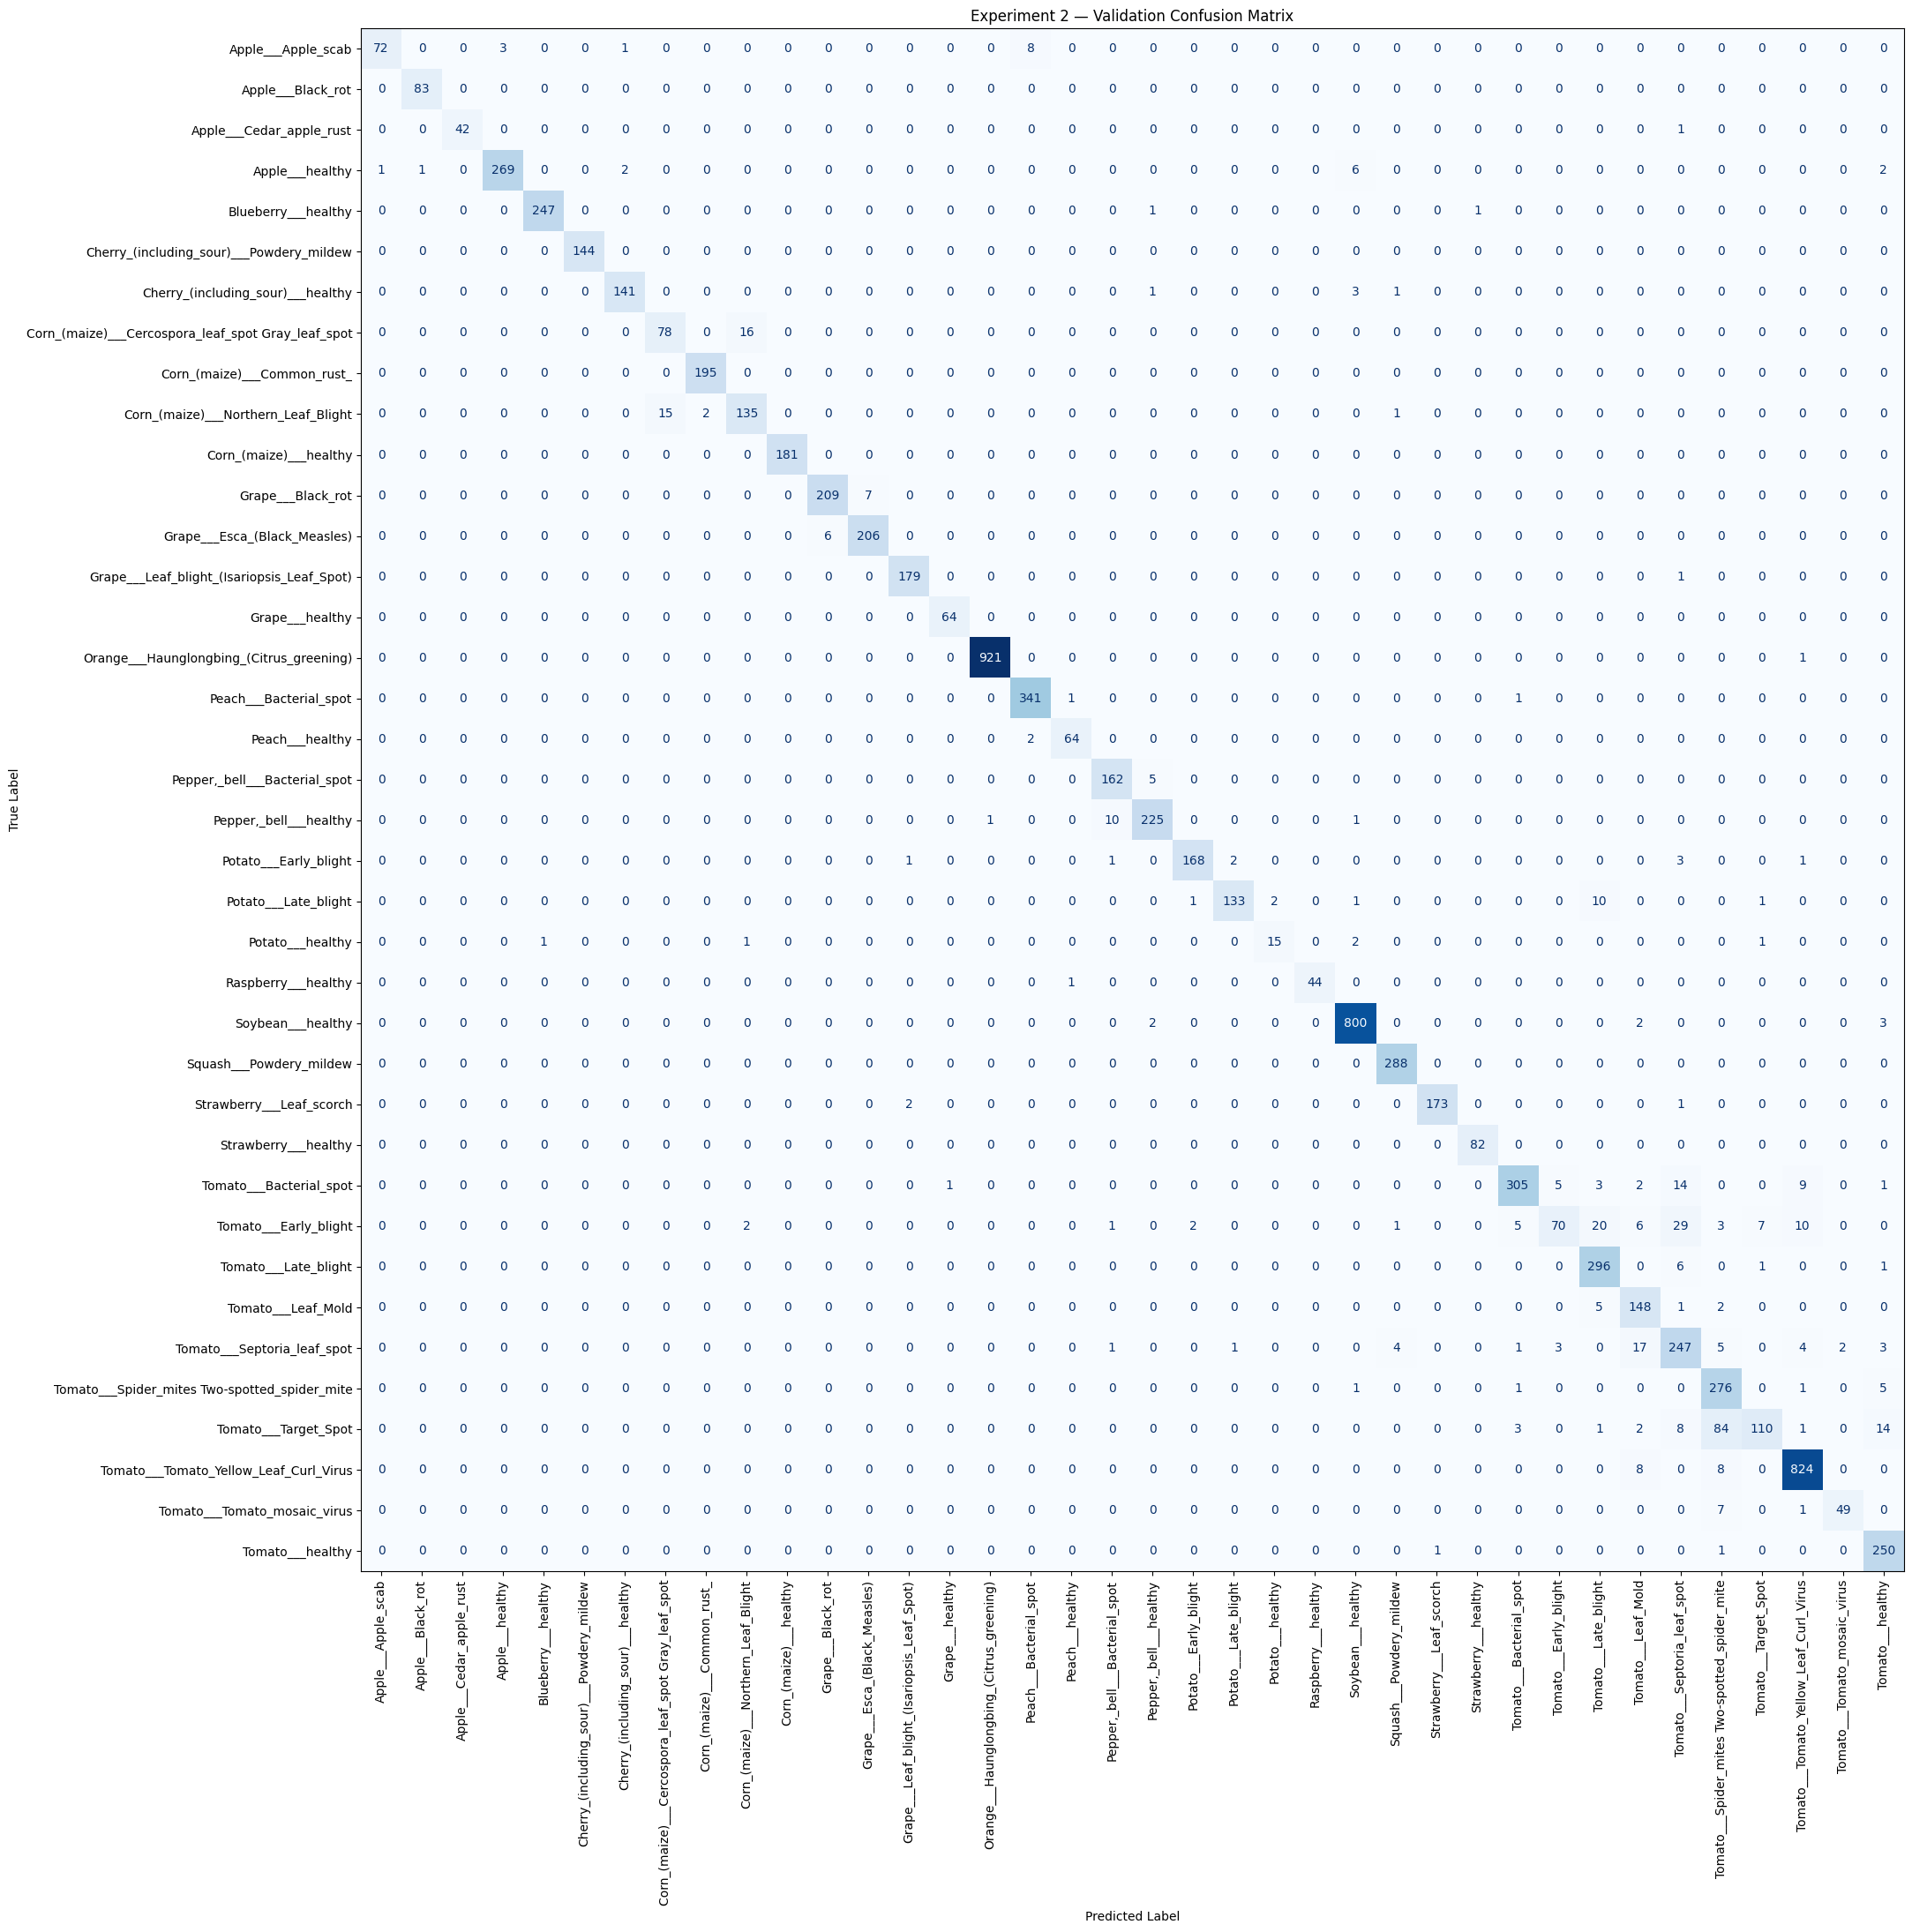

In [57]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

fig, ax = plt.subplots(figsize=(22, 22))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

plt.title("Experiment 2 — Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

In [58]:
confusion_without_diagonal = cm.copy()
np.fill_diagonal(confusion_without_diagonal, 0)

# Get the largest off-diagonal values
confusion_pairs = []

for true_index in range(len(class_names)):
    for predicted_index in range(len(class_names)):
        count = confusion_without_diagonal[
            true_index, predicted_index
        ]

        if count > 0:
            confusion_pairs.append({
                "Actual Disease": class_names[true_index],
                "Predicted Disease": class_names[predicted_index],
                "Misclassified Images": count
            })

confusion_pairs_df = pd.DataFrame(confusion_pairs)

confusion_pairs_df = confusion_pairs_df.sort_values(
    by="Misclassified Images",
    ascending=False
)

print("Top 15 Most Frequent Misclassifications")

display(confusion_pairs_df.head(15))

Top 15 Most Frequent Misclassifications


,Actual Disease,Predicted Disease,Misclassified Images
91,Tomato___Target_Spot,Tomato___Spider_mites Two-spotted_spider_mite,84
63,Tomato___Early_blight,Tomato___Septoria_leaf_spot,29
61,Tomato___Early_blight,Tomato___Late_blight,20
78,Tomato___Septoria_leaf_spot,Tomato___Leaf_Mold,17
14,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Corn_(maize)___Northern_Leaf_Blight,16
15,Corn_(maize)___Northern_Leaf_Blight,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,15
93,Tomato___Target_Spot,Tomato___healthy,14
53,Tomato___Bacterial_spot,Tomato___Septoria_leaf_spot,14
37,Potato___Late_blight,Tomato___Late_blight,10
66,Tomato___Early_blight,Tomato___Tomato_Yellow_Leaf_Curl_Virus,10



Experiment 2 used fine-tuning to adapt the pretrained MobileNetV2 feature extractor to plant disease classification. Compared with Experiment 1, which kept the pretrained base model frozen, Experiment 2 unfroze the final layers while keeping Batch Normalization layers frozen.

The validation results show a modest but consistent improvement in overall performance.

| Metric | Experiment 1: Baseline | Experiment 2: Fine-tuning |
|---|---:|---:|
| Accuracy | 0.9408 | 0.9464 |
| Loss | 0.2273 | 0.2005 |
| Macro Precision | 0.9384 | 0.9463 |
| Macro Recall | 0.9153 | 0.9278 |
| Macro F1 | 0.9224 | 0.9321 |
| Weighted Precision | 0.9417 | 0.9498 |
| Weighted Recall | 0.9408 | 0.9464 |
| Weighted F1 | 0.9387 | 0.9440 |

Fine-tuning increased validation accuracy from 94.08% to 94.64%, an improvement of 0.56 percentage points. Validation loss decreased from 0.2273 to 0.2005. Macro F1 also improved from 0.9224 to 0.9321.

These results suggest that fine-tuning helped the model learn more useful features for distinguishing plant diseases. The improvement in macro metrics is particularly encouraging because it indicates better performance across classes, rather than improvement being limited to the most represented classes.

#### Per-Class Performance Analysis

Although Experiment 2 improved the overall metrics, the per-class classification report shows that some diseases remain difficult to distinguish.

The most notable weaknesses include:

- **Tomato Early Blight:** F1-score of 0.5983 and recall of 0.4487. The model correctly identifies fewer than half of the validation images belonging to this class.
- **Tomato Target Spot:** F1-score of 0.6414 and recall of 0.4933. This class remains difficult for the model.
- **Potato Healthy:** F1-score of 0.8108 and recall of 0.7500. However, this result should be interpreted cautiously because the validation set contains only 20 examples.
- **Tomato Spider Mites:** F1-score of 0.8239. Its recall is high at 0.9718, but precision is relatively low at 0.7150, indicating that other diseases are frequently classified as spider mite damage.
- **Tomato Septoria Leaf Spot:** F1-score of 0.8247, suggesting that the model still has difficulty distinguishing this disease from visually similar conditions.

Comparing the difficult classes from Experiment 1 reveals mixed results:

- Tomato Early Blight improved from an F1-score of 0.5135 to 0.5983, but remains the weakest class.
- Potato Healthy improved from 0.8000 to 0.8108, although its small support limits confidence in the comparison.
- Tomato Mosaic Virus improved from 0.8367 to 0.9074.
- Corn Cercospora / Gray Leaf Spot improved from 0.7910 to 0.8342.
- Tomato Target Spot declined from 0.7580 to 0.6414.

Therefore, fine-tuning improved several difficult classes, but it did not improve every class. Tomato Target Spot is a particularly important weakness that requires further investigation.

#### Confusion Matrix Analysis

The confusion matrix provides further insight into the model's errors.

The most frequent misclassifications include:

| Actual Class | Predicted Class | Misclassified Images |
|---|---|---:|
| Tomato Target Spot | Tomato Spider Mites | 84 |
| Tomato Early Blight | Tomato Septoria Leaf Spot | 29 |
| Tomato Early Blight | Tomato Late Blight | 20 |
| Tomato Septoria Leaf Spot | Tomato Leaf Mold | 17 |
| Corn Cercospora / Gray Leaf Spot | Corn Northern Leaf Blight | 16 |
| Corn Northern Leaf Blight | Corn Cercospora / Gray Leaf Spot | 15 |
| Tomato Target Spot | Tomato Healthy | 14 |

The largest confusion occurs between Tomato Target Spot and Tomato Spider Mites. This suggests that the model may be learning overlapping visual characteristics between these classes.

Tomato Early Blight is also frequently confused with other tomato diseases, particularly Septoria Leaf Spot and Late Blight. Similarly, the two corn leaf diseases are confused with one another.

These findings suggest that some remaining errors are associated with visual similarities between disease symptoms rather than a general inability to classify plant images.

#### Decision: Conduct One More Experiment

Experiment 2 has improved the overall validation performance, but the per-class results reveal that some important weaknesses remain.

Rather than immediately evaluating the model on the unseen test set, we will conduct one additional targeted experiment.

**Class Imbalance and Targeted Augmentation**

The objective will be to improve performance on difficult classes, particularly:

- Tomato Early Blight
- Tomato Target Spot
- Tomato Spider Mites
- Tomato Septoria Leaf Spot
- Potato Healthy

The experiment will investigate whether class weighting can help the model pay more attention to classes where it currently makes frequent errors. We will also investigate whether carefully selected training augmentation can improve its ability to recognize variations in disease appearance.

The experiment will use the same training and validation splits. The test dataset will remain untouched.

We will avoid changing several model components simultaneously so that we can understand the effect of the selected improvement.

#### Final Model Selection Strategy

After Experiment 3, we will compare all three experiments using:

- Validation accuracy and loss.
- Macro precision, recall and F1-score.
- Weighted precision, recall and F1-score.
- Per-class classification performance.
- Confusion matrix and the most frequent misclassifications.

The final model will not necessarily be the one with the highest accuracy. We will consider its overall performance and how consistently it identifies all 38 disease classes.

Once the best-performing model has been selected using validation results, we will evaluate it on the untouched test dataset. This will provide an independent assessment of its ability to generalize to unseen images.

**Conclusion:** Experiment 2 demonstrates that fine-tuning MobileNetV2 improves overall performance compared with the frozen-feature-extractor baseline. However, persistent confusion among several tomato diseases, especially Tomato Target Spot and Tomato Early Blight, justifies one more targeted experiment before final model selection and unseen test evaluation.

### Experiment 3: Fine-tuning with Class Weighting
Experiment 3 will investigate whether class weighting can improve the model's performance on difficult disease classes without changing the model architecture.

We will start from the best Experiment 2 checkpoint and introduce class weights during training.

The main change is:
Component	Experiment 2	Experiment 3
Base model	Fine-tuned MobileNetV2	Same fine-tuned MobileNetV2
Classification head	Same	Same
Training data	Same	Same
Validation data	Same	Same
Class weighting	No	Yes
Early stopping	Yes	Yes
Learning-rate reduction	Yes	Yes

This is a controlled experiment: class weighting is the main variable we are changing.

We will calculate weights using training labels only. Classes with fewer training examples receive larger weights, so mistakes on those classes contribute more to the training loss.


In [48]:
from sklearn.utils.class_weight import compute_class_weight

# Extract labels from the training split only
train_labels = np.array(train_data["label"])

class_ids = np.unique(train_labels)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=train_labels
)

# Map class ID to its weight
class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(class_ids, class_weights)
}

class_names = train_data.features["label"].names

class_weights_df = pd.DataFrame({
    "Class ID": class_ids,
    "Disease Class": [class_names[i] for i in class_ids],
    "Training Images": [
        int(np.sum(train_labels == i)) for i in class_ids
    ],
    "Class Weight": class_weights
})

print("Number of training images:", len(train_labels))
print("Number of classes:", len(class_ids))
print("\nClass weights — lowest weights first:")

display(
    class_weights_df.sort_values(
        by="Class Weight",
        ascending=True
    ).style.format({
        "Class Weight": "{:.4f}"
    })
)

Number of training images: 34880
Number of classes: 38

Class weights — lowest weights first:


,Class ID,Disease Class,Training Images,Class Weight
15,15,Orange___Haunglongbing_(Citrus_greening),3605,0.2546
35,35,Tomato___Tomato_Yellow_Leaf_Curl_Virus,3417,0.2686
24,24,Soybean___healthy,3310,0.2773
16,16,Peach___Bacterial_spot,1412,0.6501
28,28,Tomato___Bacterial_spot,1351,0.6794
30,30,Tomato___Late_blight,1225,0.7493
25,25,Squash___Powdery_mildew,1169,0.7852
32,32,Tomato___Septoria_leaf_spot,1146,0.8010
3,3,Apple___healthy,1073,0.8554
33,33,Tomato___Spider_mites Two-spotted_spider_mite,1072,0.8562


In [65]:
experiment2_model_path = (
    "/kaggle/input/datasets/janvieremunezero/"
    "leaflens-trained-models/best_mobilenetv2_finetuned.keras"
)

In [66]:
# Load the best Experiment 2 checkpoint
model_exp3 = tf.keras.models.load_model(
    experiment2_model_path
)

# Retrieve the pretrained MobileNetV2 feature extractor
base_model_exp3 = model_exp3.get_layer(
    "mobilenetv2_1.00_224"
)

# Reapply the Experiment 2 fine-tuning policy
base_model_exp3.trainable = True

# Freeze all layers first
for layer in base_model_exp3.layers:
    layer.trainable = False

# Unfreeze the final 30 layers, except Batch Normalization
for layer in base_model_exp3.layers[-30:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True

# Count trainable and non-trainable base-model layers
trainable_base_layers = sum(
    layer.trainable for layer in base_model_exp3.layers
)

non_trainable_base_layers = sum(
    not layer.trainable for layer in base_model_exp3.layers
)

print("Experiment 3 model prepared.")
print("Total MobileNetV2 layers:", len(base_model_exp3.layers))
print("Trainable base-model layers:", trainable_base_layers)
print("Non-trainable base-model layers:", non_trainable_base_layers)

Experiment 3 model prepared.
Total MobileNetV2 layers: 154
Trainable base-model layers: 19
Non-trainable base-model layers: 135


In [67]:
model_exp3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-6
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Experiment 3 compiled successfully.")
print("Initial learning rate:", 1e-6)

Experiment 3 compiled successfully.
Initial learning rate: 1e-06


In [68]:
# Convert class weights to a TensorFlow tensor
class_weights_tensor = tf.constant(
    class_weights,
    dtype=tf.float32
)

# Attach the appropriate weight to each label
def add_sample_weights(images, labels):
    sample_weights = tf.gather(
        class_weights_tensor,
        tf.cast(labels, tf.int32)
    )

    return images, labels, sample_weights

train_dataset_exp3 = train_dataset.map(
    add_sample_weights,
    num_parallel_calls=tf.data.AUTOTUNE
)

print("Weighted training dataset prepared.")

# Inspect one batch
for images, labels, sample_weights in train_dataset_exp3.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Sample-weight shape:", sample_weights.shape)
    print("Sample weights:", sample_weights[:10].numpy())

Weighted training dataset prepared.
Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Sample-weight shape: (32,)
Sample weights: [1.4342105 1.4342105 2.9419703 1.4342105 1.4342105 2.9419703 1.4342105
 1.4342105 1.4342105 1.4342105]


In [70]:
experiment3_dir = Path(
    "/kaggle/working/plant_disease_artifacts/"
    "experiment_03_class_weighting"
)

experiment3_dir.mkdir(
    parents=True,
    exist_ok=True
)

best_model_exp3_path = (
    experiment3_dir / "best_mobilenetv2_class_weighted.keras"
)

history_exp3_path = (
    experiment3_dir / "training_history.csv"
)

callbacks_exp3 = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_exp3_path),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-8,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    tf.keras.callbacks.CSVLogger(
        filename=str(history_exp3_path)
    )
]

print("Experiment 3 callbacks configured.")
print("Best model will be saved to:", best_model_exp3_path)
print("Training history will be saved to:", history_exp3_path)

Experiment 3 callbacks configured.
Best model will be saved to: /kaggle/working/plant_disease_artifacts/experiment_03_class_weighting/best_mobilenetv2_class_weighted.keras
Training history will be saved to: /kaggle/working/plant_disease_artifacts/experiment_03_class_weighting/training_history.csv


In [72]:
EPOCHS = 40

steps_per_epoch = math.ceil(
    len(train_data) / BATCH_SIZE
)

validation_steps = math.ceil(
    len(val_data) / BATCH_SIZE
)

print("Training examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Steps per epoch:", steps_per_epoch)
print("Validation steps:", validation_steps)

history_exp3 = model_exp3.fit(
    train_dataset_exp3,
    validation_data=val_dataset,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_steps=validation_steps,
    callbacks=callbacks_exp3,
    verbose=1
)

Training examples: 34880
Validation examples: 8702
Steps per epoch: 1090
Validation steps: 272
Epoch 1/40
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9643 - loss: 0.1812
Epoch 1: val_loss improved from 0.23166 to 0.17047, saving model to /kaggle/working/plant_disease_artifacts/experiment_03_class_weighting/best_mobilenetv2_class_weighted.keras

Epoch 1: finished saving model to /kaggle/working/plant_disease_artifacts/experiment_03_class_weighting/best_mobilenetv2_class_weighted.keras
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 231s 210ms/step - accuracy: 0.9679 - loss: 0.1293 - val_accuracy: 0.9546 - val_loss: 0.1705 - learning_rate: 2.0000e-07
Epoch 2/40

Epoch 2: val_loss did not improve from 0.17047
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.9546 - val_loss: 0.1705 - learning_rate: 2.0000e-07
Epoch 3/40
1090/1090 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.9632 - loss: 0.1744
Epoch 3: val_loss did not improve from 

In [74]:
experiment3_model_path = Path(
    "/kaggle/working/plant_disease_artifacts/"
    "experiment_03_class_weighting/"
    "best_mobilenetv2_class_weighted.keras"
)

assert experiment3_model_path.is_file(), (
    f"Model checkpoint not found: {experiment3_model_path}"
)

model_exp3 = tf.keras.models.load_model(
    experiment3_model_path,
    compile=False
)

print("Experiment 3 model loaded successfully.")
print("Model:", model_exp3.name)
print("Output shape:", model_exp3.output_shape)

Experiment 3 model loaded successfully.
Model: plant_disease_mobilenetv2
Output shape: (None, 38)


In [77]:
y_true_exp3 = np.concatenate([
    labels.numpy()
    for _, labels in val_dataset
])

y_prob_exp3 = model_exp3.predict(val_dataset, verbose=1)
y_pred_exp3 = np.argmax(y_prob_exp3, axis=1)

exp3_metrics = {
    "Accuracy": accuracy_score(y_true_exp3, y_pred_exp3),
    "Macro Precision": precision_score(
        y_true_exp3, y_pred_exp3, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true_exp3, y_pred_exp3, average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true_exp3, y_pred_exp3, average="macro", zero_division=0
    ),
    "Weighted Precision": precision_score(
        y_true_exp3, y_pred_exp3, average="weighted", zero_division=0
    ),
    "Weighted Recall": recall_score(
        y_true_exp3, y_pred_exp3, average="weighted", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_true_exp3, y_pred_exp3, average="weighted", zero_division=0
    )
}

print("EXPERIMENT 3: VALIDATION METRICS")
for metric, value in exp3_metrics.items():
    print(f"{metric}: {value:.4f}")

272/272 ━━━━━━━━━━━━━━━━━━━━ 15s 54ms/step
EXPERIMENT 3: VALIDATION METRICS
Accuracy: 0.9574
Macro Precision: 0.9466
Macro Recall: 0.9455
Macro F1: 0.9452
Weighted Precision: 0.9580
Weighted Recall: 0.9574
Weighted F1: 0.9571


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [78]:
print("Actual validation labels:", len(y_true_exp3))
print("Predicted validation labels:", len(y_pred_exp3))

assert len(y_true_exp3) == 8702
assert len(y_pred_exp3) == 8702

report_exp3 = classification_report(
    y_true_exp3,
    y_pred_exp3,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_exp3_df = pd.DataFrame(report_exp3).T

# Show individual disease classes only
class_report_exp3 = report_exp3_df.iloc[:len(class_names)]

display(
    class_report_exp3[
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

Actual validation labels: 8702
Predicted validation labels: 8702


,precision,recall,f1-score,support
Apple___Apple_scab,0.9737,0.8810,0.9250,84.0
Apple___Black_rot,0.9765,1.0000,0.9881,83.0
Apple___Cedar_apple_rust,1.0000,1.0000,1.0000,43.0
Apple___healthy,0.9928,0.9751,0.9838,281.0
Blueberry___healthy,0.9920,0.9920,0.9920,249.0
Cherry_(including_sour)___Powdery_mildew,1.0000,1.0000,1.0000,144.0
Cherry_(including_sour)___healthy,0.9792,0.9658,0.9724,146.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.7810,0.8723,0.8241,94.0
Corn_(maize)___Common_rust_,0.9898,1.0000,0.9949,195.0
Corn_(maize)___Northern_Leaf_Blight,0.8980,0.8627,0.8800,153.0



Experiment 3 was selected as the final candidate based on its superior validation performance. It uses MobileNetV2 pretrained on ImageNet, fine-tuned by unfreezing selected layers while keeping Batch Normalization layers frozen. Class weighting was introduced to address class imbalance by giving greater importance to underrepresented disease classes during training. The model achieved 95.74% validation accuracy and a macro F1-score of 94.52% across 38 classes. This experiment demonstrated improved overall classification performance and better recognition of several previously difficult disease categories.

In [79]:
print("Test examples:", test_data.num_rows)
print("Number of classes:", len(class_names))

print("\nTest dataset pipeline:")
print(test_dataset)

Test examples: 10464
Number of classes: 38

Test dataset pipeline:
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))>


In [82]:
model_exp3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Experiment 3 compiled successfully.")

Experiment 3 compiled successfully.


In [83]:
test_loss_exp3, test_accuracy_exp3 = model_exp3.evaluate(
    test_dataset,
    verbose=1
)

print("\nEXPERIMENT 3 — FINAL TEST RESULTS")
print(f"Test Loss: {test_loss_exp3:.4f}")
print(f"Test Accuracy: {test_accuracy_exp3:.4f}")
print(f"Test Accuracy (%): {test_accuracy_exp3 * 100:.2f}%")

327/327 ━━━━━━━━━━━━━━━━━━━━ 24s 61ms/step - accuracy: 0.9584 - loss: 0.1664

EXPERIMENT 3 — FINAL TEST RESULTS
Test Loss: 0.1664
Test Accuracy: 0.9584
Test Accuracy (%): 95.84%


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


In [84]:
# Extract actual labels from the test dataset
y_true_test = np.concatenate([
    labels.numpy()
    for _, labels in test_dataset
])

# Generate predictions
y_prob_test = model_exp3.predict(test_dataset, verbose=1)
y_pred_test = np.argmax(y_prob_test, axis=1)

# Calculate classification metrics
test_metrics_exp3 = {
    "Accuracy": accuracy_score(y_true_test, y_pred_test),
    "Macro Precision": precision_score(
        y_true_test, y_pred_test,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true_test, y_pred_test,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_true_test, y_pred_test,
        average="macro", zero_division=0
    ),
    "Weighted Precision": precision_score(
        y_true_test, y_pred_test,
        average="weighted", zero_division=0
    ),
    "Weighted Recall": recall_score(
        y_true_test, y_pred_test,
        average="weighted", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_true_test, y_pred_test,
        average="weighted", zero_division=0
    )
}

print("EXPERIMENT 3: FINAL TEST METRICS")
for metric, value in test_metrics_exp3.items():
    print(f"{metric}: {value:.4f}")

print("\nNumber of actual labels:", len(y_true_test))
print("Number of predictions:", len(y_pred_test))

327/327 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step
EXPERIMENT 3: FINAL TEST METRICS
Accuracy: 0.9584
Macro Precision: 0.9443
Macro Recall: 0.9513
Macro F1: 0.9465
Weighted Precision: 0.9595
Weighted Recall: 0.9584
Weighted F1: 0.9580

Number of actual labels: 10464
Number of predictions: 10464


In [85]:
test_report_exp3 = classification_report(
    y_true_test,
    y_pred_test,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

test_report_exp3_df = pd.DataFrame(test_report_exp3).T

display(
    test_report_exp3_df.iloc[:len(class_names)][
        ["precision", "recall", "f1-score", "support"]
    ].round(4)
)

,precision,recall,f1-score,support
Apple___Apple_scab,0.9831,0.9134,0.9469,127.0
Apple___Black_rot,0.9931,0.9795,0.9862,146.0
Apple___Cedar_apple_rust,0.9286,1.0000,0.9630,52.0
Apple___healthy,0.9656,0.9894,0.9774,284.0
Blueberry___healthy,0.9938,0.9938,0.9938,324.0
Cherry_(including_sour)___Powdery_mildew,0.9820,0.9954,0.9887,219.0
Cherry_(including_sour)___healthy,0.9685,1.0000,0.9840,123.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.7238,0.8636,0.7876,88.0
Corn_(maize)___Common_rust_,0.9863,0.9954,0.9908,217.0
Corn_(maize)___Northern_Leaf_Blight,0.9266,0.8454,0.8841,194.0


### Final Model Evaluation on the Unseen Test Set

Experiment 3 achieved **95.84% test accuracy** with a test loss of **0.1664**, demonstrating strong generalization to previously unseen images. The per-class classification report shows consistently high performance across most of the 38 disease categories. Several classes achieved F1-scores above 0.98, including Orange Huanglongbing, Grape healthy, Strawberry Leaf Scorch, and Squash Powdery Mildew. However, Tomato Early Blight (F1: 0.6981) and Corn Cercospora Leaf Spot (F1: 0.7876) remain challenging, indicating opportunities for further improvement. Potato Healthy also recorded a comparatively lower F1-score of 0.8182, with only 32 test examples. Overall, the model demonstrates strong classification performance across multiple crops and disease categories. Experiment 3 is therefore selected as the final model candidate for deployment. Its trained checkpoint will be preserved as a project artifact for integration into the prediction interface and future retraining workflows.

In [86]:
# Create a dedicated final model directory
final_model_dir = Path(
    "/kaggle/working/plant_disease_artifacts/final_model"
)
final_model_dir.mkdir(parents=True, exist_ok=True)

# Copy the selected Experiment 3 checkpoint
final_model_path = (
    final_model_dir / "leaflens_final_model.keras"
)

shutil.copy2(
    experiment3_model_path,
    final_model_path
)

print("Final model saved successfully.")
print("Model path:", final_model_path)
print("File size (MB):", round(
    final_model_path.stat().st_size / (1024 * 1024), 2
))

Final model saved successfully.
Model path: /kaggle/working/plant_disease_artifacts/final_model/leaflens_final_model.keras
File size (MB): 21.26


In [87]:
final_model = tf.keras.models.load_model(
    final_model_path,
    compile=False
)

print("Final model verification successful.")
print("Input shape:", final_model.input_shape)
print("Output shape:", final_model.output_shape)
print("Number of classes:", final_model.output_shape[-1])

Final model verification successful.
Input shape: (None, 224, 224, 3)
Output shape: (None, 38)
Number of classes: 38


In [88]:
# Save class names in their original label order
class_names_path = final_model_dir / "class_names.json"

with open(class_names_path, "w") as f:
    json.dump(list(class_names), f, indent=4)

# Save preprocessing configuration
preprocessing_config = {
    "architecture": "MobileNetV2",
    "image_size": [224, 224],
    "color_mode": "RGB",
    "input_range": [-1, 1],
    "preprocessing": "mobilenet_v2.preprocess_input",
    "num_classes": 38,
    "model_filename": "leaflens_final_model.keras"
}

config_path = final_model_dir / "preprocessing_config.json"

with open(config_path, "w") as f:
    json.dump(preprocessing_config, f, indent=4)

print("Supporting artifacts saved successfully.")
print("Class mapping:", class_names_path)
print("Preprocessing config:", config_path)

Supporting artifacts saved successfully.
Class mapping: /kaggle/working/plant_disease_artifacts/final_model/class_names.json
Preprocessing config: /kaggle/working/plant_disease_artifacts/final_model/preprocessing_config.json


In [89]:
# Final artifact directory
final_model_dir = Path("/kaggle/working/plant_disease_artifacts/final_model")

# Expected artifact paths
final_model_path = final_model_dir / "leaflens_final_model.keras"
class_names_path = final_model_dir / "class_names.json"
config_path = final_model_dir / "preprocessing_config.json"

# Check that all three files exist
artifacts = {
    "Final model": final_model_path,
    "Class names": class_names_path,
    "Preprocessing config": config_path
}

print("FINAL MODEL ARTIFACT VERIFICATION")
print("=" * 45)

for name, path in artifacts.items():
    if not path.exists():
        raise FileNotFoundError(f"{name} is missing: {path}")

    print(f"{name}: FOUND ({path.stat().st_size / (1024 * 1024):.2f} MB)")

# Verify class mapping
with open(class_names_path, "r") as f:
    saved_class_names = json.load(f)

assert len(saved_class_names) == 38
assert saved_class_names == list(class_names)

# Verify preprocessing configuration
with open(config_path, "r") as f:
    saved_config = json.load(f)

assert saved_config["image_size"] == [224, 224]
assert saved_config["color_mode"] == "RGB"
assert saved_config["num_classes"] == 38

# Verify that the saved model can be loaded
verified_model = tf.keras.models.load_model(
    final_model_path,
    compile=False
)

assert verified_model.input_shape == (None, 224, 224, 3)
assert verified_model.output_shape == (None, 38)

print("ALL THREE ARTIFACTS VERIFIED SUCCESSFULLY.")
print("Model input:", verified_model.input_shape)
print("Model output:", verified_model.output_shape)
print("Number of classes:", len(saved_class_names))

FINAL MODEL ARTIFACT VERIFICATION
Final model: FOUND (21.26 MB)
Class names: FOUND (0.00 MB)
Preprocessing config: FOUND (0.00 MB)
ALL THREE ARTIFACTS VERIFIED SUCCESSFULLY.
Model input: (None, 224, 224, 3)
Model output: (None, 38)
Number of classes: 38


## Conclusion

This notebook completed the development and evaluation of a 38-class plant disease classification model using the PlantVillage dataset.

Three experiments were conducted using MobileNetV2 pretrained on ImageNet:

- **Experiment 1:  Baseline** Trained a classification head while keeping the pretrained feature extractor frozen.
- **Experiment 2: Fine-tuning:** Unfroze selected layers of MobileNetV2 to adapt pretrained features to plant disease classification.
- **Experiment 3: Class-weighted fine-tuning:** Introduced class weights during training to address class imbalance and improve recognition of underrepresented disease categories.

Experiment 3 was selected as the final model because it achieved the strongest overall validation performance, with 95.74% validation accuracy and a 94.52% macro F1-score. Its final test evaluation achieved 95.84% accuracy and a test loss of 0.1664, demonstrating strong performance on previously unseen test images.

The final model was saved as `leaflens_final_model.keras` and successfully reloaded and verified. Its supporting artifacts, `class_names.json` and `preprocessing_config.json`, were also saved and verified to ensure consistent class interpretation and image preprocessing during application development.

The project has therefore completed its data preparation, model development, experimentation, evaluation, and final model preservation stages.

**Next Phase:** The selected model will be integrated into the LeafLens application, which will support plant disease prediction, the addition of new labeled images, model retraining, and deployment through a user-friendly interface.